#  Лабораторная работа №1 «Дискретизация аналоговых сигналов»



Курс: Радиофизическая лаборатория (ФРКТ МФТИ).

LMS: https://lms.mipt.ru/course/view.php?id=1569&type=lab
* В имени этого файла заменить familyname на Ваши фамилию и имя, либо только фамилию.  

# Занятие 1. Классификация сигналов: аналоговые, дискретные, цифровые.

In [6]:
import numpy as np                # импорт бибилиотеки numpy
import matplotlib.pyplot as plt   # импорт модуля matplotlib.pyplot
import scipy.io.wavfile # импорт модуля scipy.io.wavfile

In [7]:
# Для использования backend matplotlib inline/widget/notebook, раскомментируйте соответствующую строку ниже.
# Backend notebook используется в старых версиях. 
# Установка widget: pip install --upgrade jupyterlab ipympl
%matplotlib inline
# %matplotlib notebook
# %matplotlib widget

In [8]:
def quantize_uniform(x, quant_min=-1, quant_max=1, quant_level=5):
    """Uniform quantization approach
    From: Müller M. Fundamentals of music processing: Audio, analysis, algorithms, applications. – Springer, 2015.
    Notebook: C2S2_DigitalSignalQuantization.ipynb
    Args:
        x: Original signal
        quant_min: Minimum quantization level
        quant_max: Maximum quantization level
        quant_level: Number of quantization levels
    Returns:
        x_quant: Quantized signal
    """
    x_normalize = (x-quant_min) * (quant_level-1) / (quant_max-quant_min)
    x_normalize[x_normalize > quant_level - 1] = quant_level - 1
    x_normalize[x_normalize < 0] = 0
    x_normalize_quant = np.around(x_normalize)
    x_quant = (x_normalize_quant) * (quant_max-quant_min) / (quant_level-1) + quant_min
    return x_quant

In [9]:
import scipy.integrate as integrate # импорт модуля численного интегрирования
def integrate_function(t, func, f, tau, real_part=True):
    # Подынтегральное выражение для использованиия в функции integrate.quad
    # t - время
    # func - функция, задающая импульс
    # f - частота
    # tau - константа, используемая для задания длительности импульса
    if real_part:
        return func(t, tau)*np.cos(-2*np.pi*f*t)  # действительная часть интеграла
    else:
        return func(t, tau)*np.sin(-2*np.pi*f*t)  # мнимая часть интеграла
def fourier_transform(signal, f_band, tau, t1, t2, res_type='abs'):
    # вычисление преобразования Фурье для набора частот
    # signal - функция от t и tau, задающая сигнал во временной области 
    # f_band - набор частот, для которых вычисляется преобразование Фурье
    # tau - константа, используемая для задания длительности импульса
    # t1 момент начала сигнала
    # t2 момент завершения сигнала
    # тип возвращаемого значения:
    # res_type='abs' - |X(f)|
    # res_type='Re' - Re X(f)
    # res_type='Im' - Im X(f)
    if res_type=="abs":
        Re=np.array([integrate.quad(integrate_function, t1, t2, args=(signal, f, tau, True))[0] for f in f_band])
        Im=np.array([integrate.quad(integrate_function, t1, t2, args=(signal, f, tau, False))[0] for f in f_band])
        return abs(Re+1j*Im)
    elif res_type=="Re":
        Re=np.array([integrate.quad(integrate_function, t1, t2, args=(signal, f, tau, True))[0] for f in f_band])
        return Re
    elif res_type=="Im":
        Im=np.array([integrate.quad(integrate_function, t1, t2, args=(signal, f, tau, False))[0] for f in f_band])
        return Im

## Задача 0. Введение в Python 3. (Задание к допуску)

1) Подгрузить библиотеку *Numpy* (`import numpy as np`).

2) Создать массив от 1 до 10 с шагом 2 – [1, 3, 5, 7, 9] – тремя разными способами (используя  три разные функции `np.array()`, `np.arange()`, `np.linspace()`).

3) Создать массив целых чисел от 0 до 100 (размерностью 100 элементов) максимально короткой записью.

4) Создать массив `k`, такой же как описан в п.3. Используя его, создать массив (набор отсчетов) `x`, соответствующий формуле $x[k] = \sin(2\pi \dfrac{f_0}{f_s}k)$, где $\dfrac{f_0}{f_s}$ взять равным 0.07. Следует использовать функцию `np.sin()` и константу `np.pi`.

5) Подгрузить модуль *pyplot* библиотеки *Matplotlib* (`import matplotlib.pyplot as plt`).

6) Создать холст (другие названия полотно, канва) размером 12 на 5 дюйма (`figsize = [12, 5]`).

7) Построить график $x[k]$ (`plt.plot(k, x)`), сделать подписи осей и заголовок графика.

8) Поменять цвет линии графика из п.7 на красный или оранжевый и тип линии на пунктир. Построить на графике отсчеты $x[k]$ с помощью функции `plt.stem(k, x)`, см. Задача 1.1 и Задача 1.2.  
(Для того чтобы поменять тип линии на пунктир, нужно в параметре отвечающем за цвет поставить модификатор "--", например `'--b'`.)

9) Работа с функциями.
  1. Создать функцию, соответствующую формуле $\dfrac{\sin(x)}{x}$. `def my_fun(x):`
  2. Незабыть обработать неопределенность в 0.  
  `if x=0:`  
  ....`return 1`  
  `else`  
  ....`return np.sin(x)/x`
  3. Выполнить п.4 и п.7, создав новый массив значений `y`, используя созданную вами функцию.

10)  Выполнить п.4, только для массива `z`, который соответствует комплексной экспоненциальной функции $z[k] = \exp(-j\,2\pi\,\dfrac{f_0}{f_s}k)$  (функция `np.exp()`). Выполнить п.7, но построить отдельно график реальной и график мнимой частей этой функции.

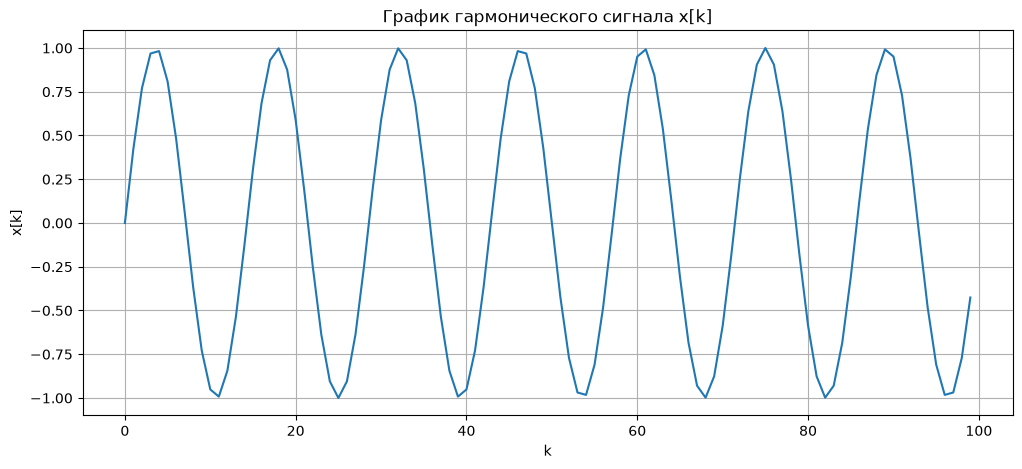

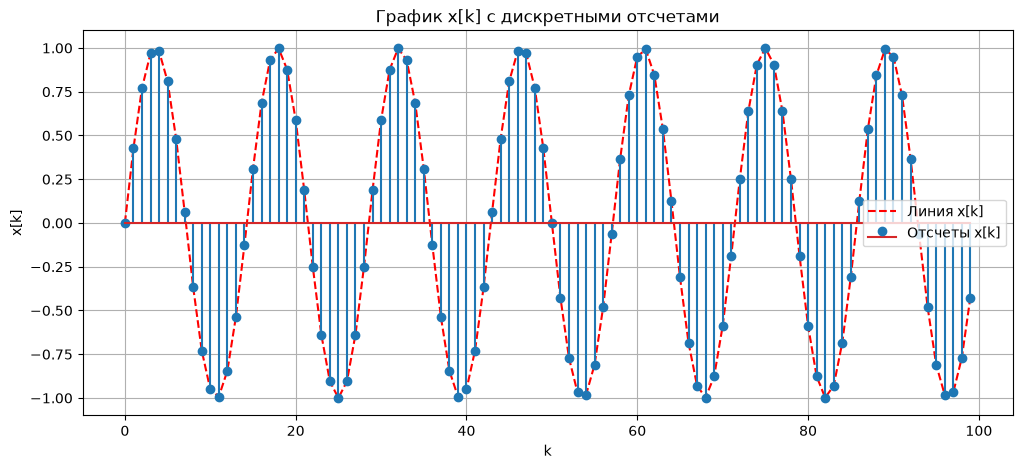

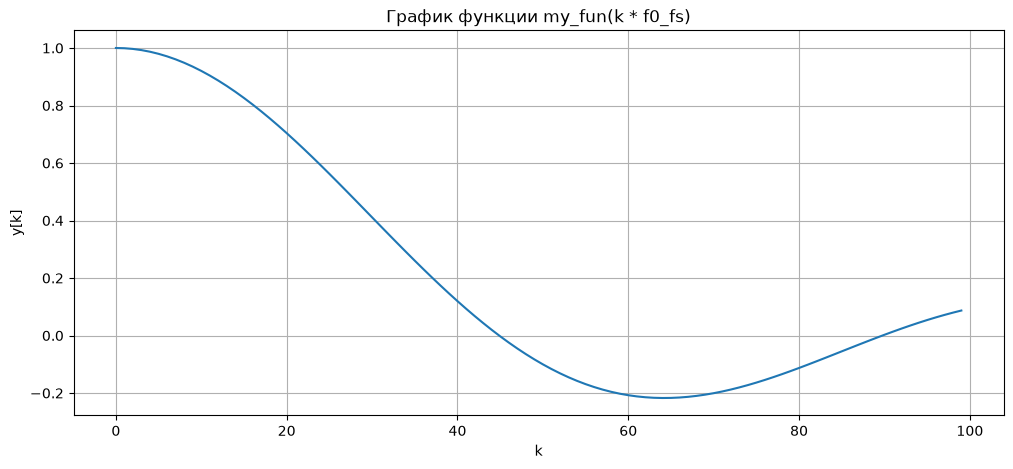

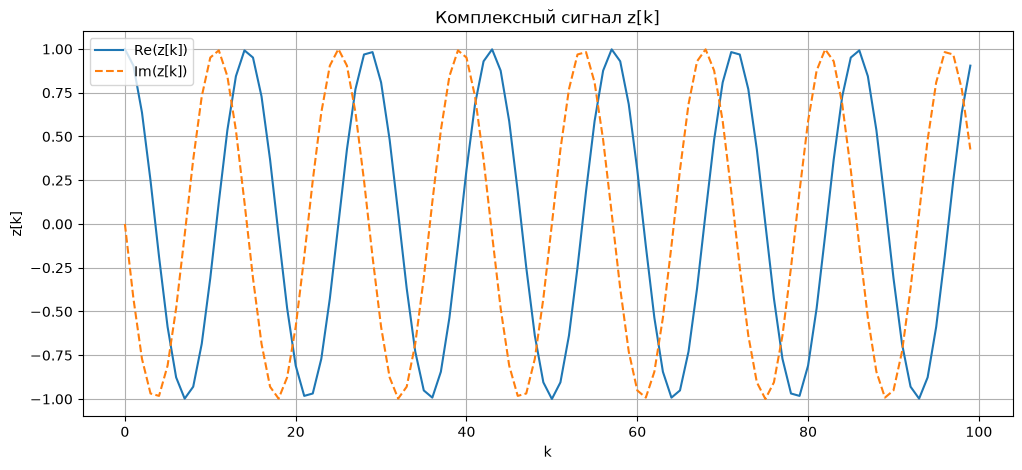

In [10]:
# 1) Подгрузить библиотеку *Numpy* (`import numpy as np`).
import numpy as np

# 2) Создать массив от 1 до 10 с шагом 2 – [1, 3, 5, 7, 9] – тремя разными способами (используя  три разные функции `np.array()`, `np.arange()`, `np.linspace()`).

arr1 = np.array([1, 3, 5, 7, 9])
arr2 = np.arange(1, 10, 2)
arr3 = np.linspace(1, 9, 5, dtype=int)

# 3) Создать массив целых чисел от 0 до 100 (размерностью 100 элементов) максимально короткой записью.

k = np.arange(100)

# 4) Создать массив `k`, такой же как описан в п.3. Используя его, создать массив (набор отсчетов) `x`, соответствующий формуле $x[k] = \sin(2\pi \dfrac{f_0}{f_s}k)$, где $\dfrac{f_0}{f_s}$ взять равным 0.07. Следует использовать функцию `np.sin()` и константу `np.pi`.

f0_fs = 0.07
x = np.sin(2 * np.pi * f0_fs * k)

# 5) Подгрузить модуль *pyplot* библиотеки *Matplotlib* (`import matplotlib.pyplot as plt`).

import matplotlib.pyplot as plt

# 6) Создать холст (другие названия полотно, канва) размером 12 на 5 дюйма (`figsize = [12, 5]`).

plt.figure(figsize=[12, 5])

# 7) Построить график $x[k]$ (`plt.plot(k, x)`), сделать подписи осей и заголовок графика.

plt.plot(k, x)
plt.xlabel("k")
plt.ylabel("x[k]")
plt.title("График гармонического сигнала x[k]")
plt.grid(True)
plt.show()

# 8) Поменять цвет линии графика из п.7 на красный или оранжевый и тип линии на пунктир. Построить на графике отсчеты $x[k]$ с помощью функции `plt.stem(k, x)`, см. Задача 1.1 и Задача 1.2.  
# (Для того чтобы поменять тип линии на пунктир, нужно в параметре отвечающем за цвет поставить модификатор "--", например `'--b'`.)

plt.figure(figsize=[12, 5])
plt.plot(k, x, "--r", label="Линия x[k]")  # Красный пунктир
plt.stem(k, x, label="Отсчеты x[k]")
plt.xlabel("k")
plt.ylabel("x[k]")
plt.title("График x[k] с дискретными отсчетами")
plt.legend()
plt.grid(True)
plt.show()


# 9) Работа с функциями.
#   1. Создать функцию, соответствующую формуле $\dfrac{\sin(x)}{x}$. `def my_fun(x):`
#   2. Незабыть обработать неопределенность в 0.  
#   `if x=0:`  
#   ....`return 1`  
#   `else`  
#   ....`return np.sin(x)/x`

def my_fun(val):
    return np.array([1 if v == 0 else np.sin(v) / v for v in val])

#   3. Выполнить п.4 и п.7, создав новый массив значений `y`, используя созданную вами функцию.

y = my_fun(k * f0_fs)

plt.figure(figsize=[12, 5])
plt.plot(k, y)
plt.xlabel("k")
plt.ylabel("y[k]")
plt.title("График функции my_fun(k * f0_fs)")
plt.grid(True)
plt.show()

# 10)  Выполнить п.4, только для массива `z`, который соответствует комплексной экспоненциальной функции $z[k] = \exp(-j\,2\pi\,\dfrac{f_0}{f_s}k)$  (функция `np.exp()`). Выполнить п.7, но построить отдельно график реальной и график мнимой частей этой функции.
# import numpy as np
z = np.exp(-1j * 2 * np.pi * f0_fs * k)

plt.figure(figsize=[12, 5])
plt.plot(k, np.real(z), label="Re(z[k])")
plt.plot(k, np.imag(z), "--", label="Im(z[k])")
plt.xlabel("k")
plt.ylabel("z[k]")
plt.title("Комплексный сигнал z[k]")
plt.legend()
plt.grid(True)
plt.show()

## Задача 1.1. Дискретизация и квантование.

| Варианты: |   1 |    2 |    3 |   4 |    5 |    6 |    7 |    8 |    9 |   10 |   11 |   12 |
|:---------:|----:|-----:|-----:|----:|-----:|-----:|-----:|-----:|-----:|-----:|-----:|-----:|
|     **N**     |  15 |   20 |   30 |  12 |   15 |   30 |   25 |   18 |   10 |   25 |   20 |   15 |
|   $f_0$**, Гц**   | 200 |  250 |  400 | 200 |  600 |  750 | 1200 |  600 |  400 |  500 |  800 |  400 |
|   $f_s$**, Гц**   | 500 | 1250 | 2000 | 600 | 1500 | 3750 | 6000 | 1800 | 1000 | 2500 | 4000 | 1200 |

Промоделировать дискретизацию и квантование синусоидального сигнала $x(t)=\sin(2\pi f_0 t)$ с частотой дискретизации $f_s$. Пронаблюдать эффекты во временной области для отрезка сигнала из $N$ отсчетов. 

1) Как соотносится растояние между отсчетами по оси времени с частотой дискретизации? <br>
<b> ответ: обратно пропорционально </b>

2) Как изменяется максимально возможная абсолютная ошибка квантования $\varepsilon[k]=|x[k]-y[k]|$ с ростом числа уровней квантования? <br>
<b> ответ: уменьшается </b>

In [11]:
N=20                                    # Число отсчетов по времени
f0=800.0                                # Частота синусоиды в Гц
fs=4000.0                               # Частота дискретизации в Гц
k=np.arange(N)                          # Mассив времен k от 0 до N-1 с шагом 1
x=np.sin(2*np.pi*(f0/fs)*k)             # Последовательность x[k]
num_levels=8                      # число уровней квантования

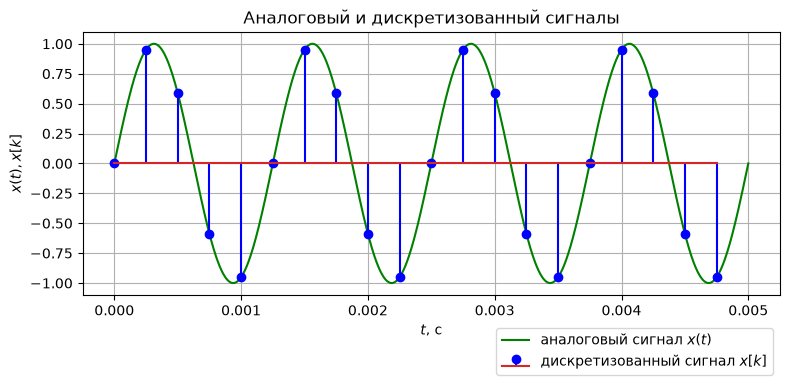

In [12]:
# Построение графиков аналогового и дискретизованного сигнала
plt.figure(figsize=[8, 4])              # создание полотна размером шириной 8 X 4 дюйма
t=np.linspace(0, N/fs, num=1024)        # создание массива времен t (1024 значения от 0 до N*fs)

plt.plot(t, np.sin(2*np.pi*f0*t), 'g', label='аналоговый сигнал $x(t)$')  
                                        # построение графика x(t) (точки соединяются линиями)
                                        # 'g' означает, что используется зеленая линия (green)
plt.stem(k/fs, x, linefmt='b', markerfmt='bo', label='дискретизованный сигнал $x[k]$')            
                                        # построение графика функции дискретного времени x[k]
                                        # 'b', 'bo' означает, что отсчеты оборажаются синим цветом (blue)
plt.grid()                              # сетка
plt.xlabel("$t$, c")                    # подпись оси X
plt.ylabel("$x(t), x[k]$")              # подпись оси Y
plt.title("Аналоговый и дискретизованный сигналы") # заголовок графика
plt.legend(loc='best', bbox_to_anchor=(1, -0.1))
plt.tight_layout()                      # автоматическая корректировка расположения осей графика
plt.show()

In [13]:
# моделирование квантования дискретного сигнала
y=quantize_uniform(x, quant_min=-1, quant_max=1, quant_level=num_levels)
bins=np.linspace(-1, 1, num_levels)

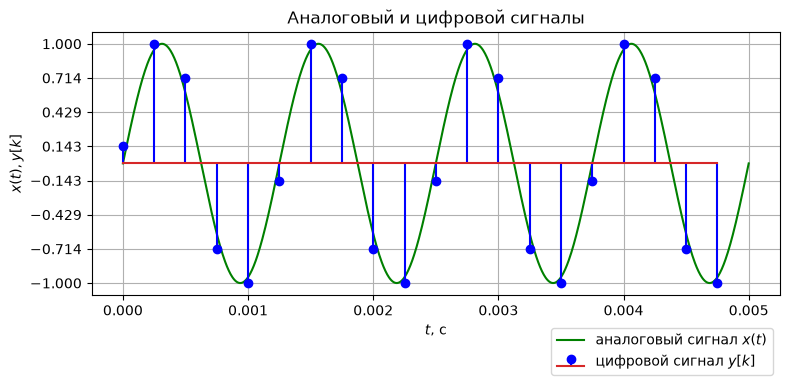

In [14]:
# Вывод графика аналогового и цифрового сигнала
plt.figure(figsize=[8, 4])                  # создание полотна размером шириной 8 X 4 дюйма
t=np.linspace(0, N/fs, num=1024)            # создание массива времен t (1024 значения от 0 до N*fs)
plt.plot(t, np.sin(2*np.pi*f0*t), 'g', label='аналоговый сигнал $x(t)$')        
                                            # построение графика x(t) (точки соединяются линиями)

plt.stem(k/fs, y, linefmt='b', markerfmt='bo', label='цифровой сигнал $y[k]$')                
                                            # построение графика функции дискретного времени y[k]
                                            # k/fs - м
    
if num_levels<21:                           # если число уровней не велико, то производится
    plt.yticks(bins)                        # установка делений шкалы оси Y, совпадающих с уровнями квантования

plt.grid()                                  # сетка
plt.xlabel("$t$, c")                        # подпись оси X
plt.ylabel("$x(t), y[k]$")                  # подпись оси Y
plt.title("Аналоговый и цифровой сигналы")  # заголовок графика
plt.legend(loc='best', bbox_to_anchor=(1, -0.1))
plt.tight_layout()                          # автоматическая корректировка расположения осей графика
plt.show()

In [15]:
abs(x-y)

array([0.14285714, 0.04894348, 0.12650046, 0.12650046, 0.04894348,
       0.14285714, 0.04894348, 0.12650046, 0.12650046, 0.04894348,
       0.14285714, 0.04894348, 0.12650046, 0.12650046, 0.04894348,
       0.14285714, 0.04894348, 0.12650046, 0.12650046, 0.04894348])

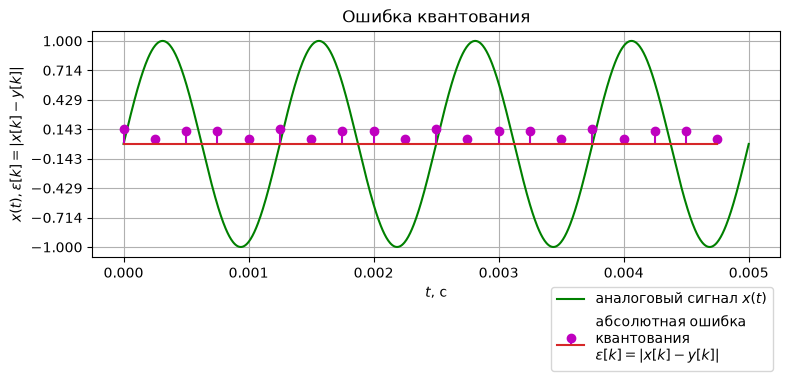

In [16]:
plt.figure(figsize=[8, 4])
plt.title("Ошибка квантования") 
plt.plot(t, np.sin(2*np.pi*f0*t), 'g', label='аналоговый сигнал $x(t)$')
plt.stem(k/fs, abs(x-y), linefmt='m', markerfmt='mo', label="абсолютная ошибка \nквантования \n$\\epsilon[k]=|x[k]-y[k]|$")       
                                      #вывод абсолютных значений ошибки квантования для дискретного сигнала
plt.yticks(bins)
plt.grid()
plt.xlabel("$t$, c")                                          # подпись оси X
plt.ylabel("$x(t), \\varepsilon[k]=|x[k]-y[k]|$")             # подпись оси Y
plt.legend(loc='best', bbox_to_anchor=(1, -0.1))
plt.tight_layout() 
plt.show()

## Задача 1.2. Декодирование .wav файла

| Варианты: |       1      |     2     |         3        |      4     |        5        |        6       |         7        |       8      |        9       |     10    |        11       |     12     |
|:---------:|:------------:|:---------:|:----------------:|:----------:|:---------------:|:--------------:|:----------------:|:------------:|:--------------:|:---------:|:---------------:|:----------:|
| **Имя файла** | clarinet.wav | flute.wav | glockenspiel.wav | guitar.wav | tuning-fork.wav | vibraphone.wav | glockenspiel.wav | clarinet.wav | vibraphone.wav | flute.wav | tuning-fork.wav | guitar.wav |

Декодируйте .wav файл в соотвествии с Вашим вариантом 11. 

1) Определите частоту дискретизации, битную глубину записи (соотвествует dtype) и соотвествующее ей колличество уровней квантования. <br>
**44100 GHz <br>
2B <br>
135680 lvls <br>**

2) Сравните растояние между отсчетами по оси времени на графике с частотой дискретизации. <br>
**это обратные величины**

3) Поменяйте ось времени (первый аргумент функции `plt.plot`) так, чтобы первому отсчету наблюдаемого диапазона соотвествовало время от начала файла. <br>


4) Определите длину записи в секундах. <br>
**3.076c**

5) Оцените объем файла в килобайтах (КБ), при условии, что никакое дополнительное сжатие не производится (использовать данные о частоте дискретизации, числе отсчетов и битовой глубине). Сравние с реальным объемом файла.  <br>
**135680 (число отсчетов) * 2 (битная глубина) = 271 360 байт = 265 КБ**

In [17]:
from IPython.display import Audio
Audio('dataset_lab1/tuning-fork.wav')

In [18]:
fs, x = scipy.io.wavfile.read('dataset_lab1/tuning-fork.wav') # чтение аудиофайла 

In [19]:
print(f'Частота дискретизации {fs} Гц')     #частота дискретизации в Гц
print(f'Битная глубина записи: {np.dtype(x[0]).itemsize} Б')
print(f'Количество уровней квантования: {x.size}')

Частота дискретизации 44100 Гц
Битная глубина записи: 2 Б
Количество уровней квантования: 135680


In [20]:
x      #массив значений x[k]

array([ 0,  0, -1, ..., -3,  2, -1], shape=(135680,), dtype=int16)

In [21]:
print(x.dtype) #тип данных для значений x[k]

int16


In [22]:
x.size #размер массива

135680

Длина записи: 3.076643990929705 сек
Настоящая длина записи: 3 сек
Размер файла: 265.0 КБ
Настойщий размер файла: 265.0 КБ


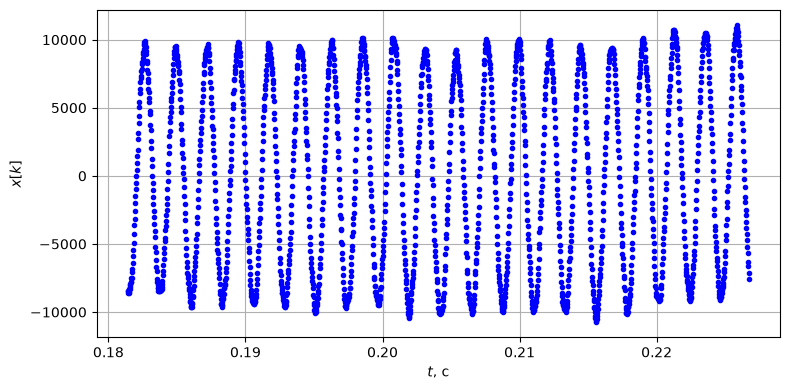

In [23]:
x1=x[8000:10000]                     # выбор наблюдаемого диапазона
k=np.arange(x1.size) + 8000          # отсчеты по времени  СМЕЩЕННЫЕ В СООТВЕТСТВИИ С 3-ИМ ЗАДАНИЕМ

print('Длина записи: ' + str(x.size / fs) + ' сек')
print('Настоящая длина записи: ' + str(3) + ' сек')
print('Размер файла: ' + str(np.dtype(x[0]).itemsize * x.size / 1024) + ' КБ')
print('Настойщий размер файла: ' + str(265.0) + ' КБ')


# Построение графиков 
plt.figure(figsize=[8, 4])         # создание полотна размером шириной 8 X 4 дюйма
plt.plot(k/fs, x1, 'b.')           # построение графика цифрового сигнала точками точками
plt.grid()                             
plt.xlabel("$t$, c")                      
plt.ylabel("$x[k]$")             
plt.tight_layout()
plt.show()

# Занятие 2. Спектры импульсных и периодических сигналов.

## Задача 2.1. Спектры симметричных оконных функций

|  Варианты:  |  1  |  2  |   3  |   4  |  5  |   6  |  7  |   8  |   9  |  10 |  11  |  12  |
|:-----------:|:---:|:---:|:----:|:----:|:---:|:----:|:---:|:----:|:----:|:---:|:----:|:----:|
| $\tau$**, мкс** | 100 | 500 | 1000 | 5000 | 400 | 2000 | 300 | 1500 | 3000 | 800 | 3500 | 4000 |


Ниже приведен пример вычисления модуля спектральной плотности $|X(f)|$ для прямоугольного окна длительностью $\tau=150$ мкс. 

Для заданного параметра $\tau$ из таблицы, построить графики модуля спектральной плотности $|X(f)|$ для прямоугольного окна, 
$$w_b(t)=\left\{ \begin{matrix}
   1, & \text{ }\text{если }|t|\le \tau /2,  \\
   0, & \text{ }\text{если }|t|>\tau /2; \\
\end{matrix} \right.$$
треугольного окна
$$w_t(t)=\left\{ \begin{matrix}
   1-\dfrac{|t|}{\tau /2}, & \text{ }\text{если }|t|\le \tau /2,  \\
   0, & \text{ }\text{если }|t|>\tau /2.  \\
\end{matrix} \right.$$
 и окна Ханна
$$w_H(t)=\left\{ \begin{matrix}
   \dfrac{1}{2}\left( 1+\cos \left( 2\pi \dfrac{t}{\tau } \right) \right), & \text{ }\text{если }|t|\le \tau /2,  \\
   0, & \text{ }\text{если }|t|>\tau /2.  \\
\end{matrix} \right.$$



Привести аналитические формулы спектральной плотности для этих импульсов. 
Определить 
* а) уровни первого бокового лепестка относительно главного в $|X(f)|$ (практич.) в дБ ($20\lg  \left|\dfrac{X(f)}{X(0)}\right| $ ),
* б) расположение нулей $|X(f)|$ (практич. и теоретическое).

Заполнить таблицу для трех окон.

| Окна  |   Уровень первого бокового лепестка относительно главного, дБ  |  Ширина главного лепестка, Гц  |
|:-----------:|:---:|:---:|
| прямоугольное |  760.27   |    577.15   |
| треугольное |  82.57   |   1145.15    |
| Ханна |  46.73   |   1145.15    |


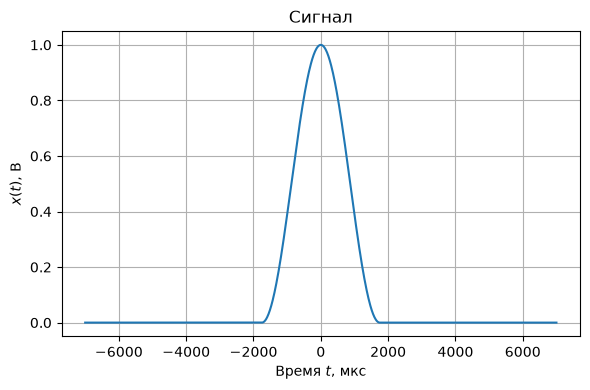

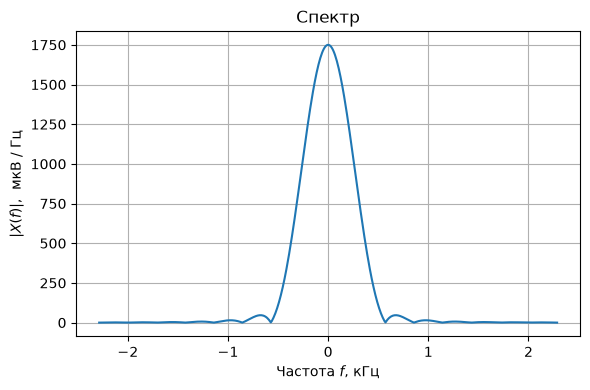

In [24]:
tau=3500e-6 #3500 мкс

f_band=np.linspace(-8/tau, 8/tau, 500) # 500 - число точек в диапазоне, в которых вычисляется X(f)

def boxcar(t, tau):
    if abs(t)<tau/2:
        return 1.0                 
    else:
        return 0.0                

def trianglecar(t, tau):
    if abs(t)<tau/2:
        return 1.0 - 2*abs(t)/tau
    else:
        return 0.0

def hanncar(t, tau):
    if abs(t)<tau/2:
        return 0.5*(1 + np.cos(2*np.pi*t/tau))
    else:
        return 0.0
    
t_band=np.linspace(-2*tau, 2*tau, 1024)
plt.figure(figsize=[6, 4])
plt.plot(t_band*1e6, [hanncar(t, tau) for t in t_band])
plt.xlabel("Время $t$, мкс")
plt.ylabel("$x(t)$, В")
plt.title("Сигнал")
plt.tight_layout() 
plt.grid()

spectre = fourier_transform(signal=hanncar, f_band=f_band, tau=tau, t1=-tau/2, t2=tau/2, res_type="abs")*1e6

plt.figure(figsize=[6, 4])
plt.plot(f_band/1e3, spectre)
plt.xlabel("Частота $f$, кГц")
plt.ylabel("$|X(f)|$,  мкВ / Гц")
plt.title("Спектр")
plt.tight_layout() 
plt.grid()
plt.show()

In [25]:
peak_lvl    = []
bot_coords  = []
for f in range(1, len(f_band)):
    if f_band[f] < 0:
        continue
    # Сравниваем текущую точку со списком/массивом
    if spectre[f] < spectre[f - 1] and spectre[f - 1] > spectre[f - 2]:
        peak_lvl.append(spectre[f - 1])
    if spectre[f] > spectre[f - 1] and spectre[f - 1] < spectre[f - 2]:
        bot_coords.append(f_band[f - 1])

    if len(peak_lvl) == 2:
        break

print(bot_coords)
print(f"thickness of main peak is {bot_coords[0] * 2}")
print(f"thickness of scnd peak is {bot_coords[1] - bot_coords[0]}")
print(f"lvl of scnd peak is {peak_lvl[0]}")



[np.float64(572.5737188663038), np.float64(856.570283423991)]
thickness of main peak is 1145.1474377326076
thickness of scnd peak is 283.9965645576872
lvl of scnd peak is 46.731115911159606


## Задача 2.2. Теорема запаздывания для преобразования Фурье

|  Варианты:  |  1  |  2  |   3  |   4  |  5  |   6  |  7  |   8  |   9  |  10 |  11  |  12  |
|:-----------:|:---:|:---:|:----:|:----:|:---:|:----:|:---:|:----:|:----:|:---:|:----:|:----:|
|     **E, В**    | 0.1 | 0.5 |   1  |   5  |  1  |   5  | 0.5 |  2.5 |   6  | 1.6 |   7  |   8  |
| **$\tau$, мкс** | 100 | 500 | 1000 | 5000 | 400 | 2000 | 300 | 1500 | 3000 | 800 | 3500 | 4000 |

Ниже приведен пример вычисления спектральной плотности для несимметричного прямоугольного импульса амплитудой $E=0.1$ В, длительностью $\tau=100$ мкс. В данном случае импульс начинается в начале отсчета оси времени. 

Для заданных параметров $E$ и $\tau$ из таблицы, построить и сравнить графики $\text{Re} X(f)$, $\text{Im} X(f)$, $|X(f)|$ для прямоугольного импульса, начинающегося в моменты времени $-\tau /2$ и $0$. Как согласуются результаты с теоремой запаздывания для преобразования Фурье?


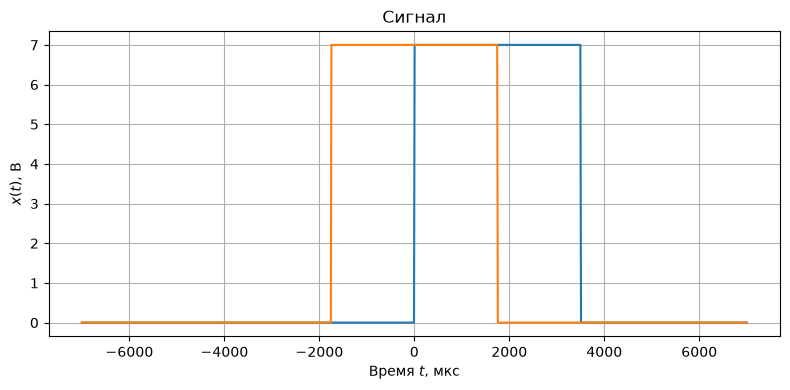

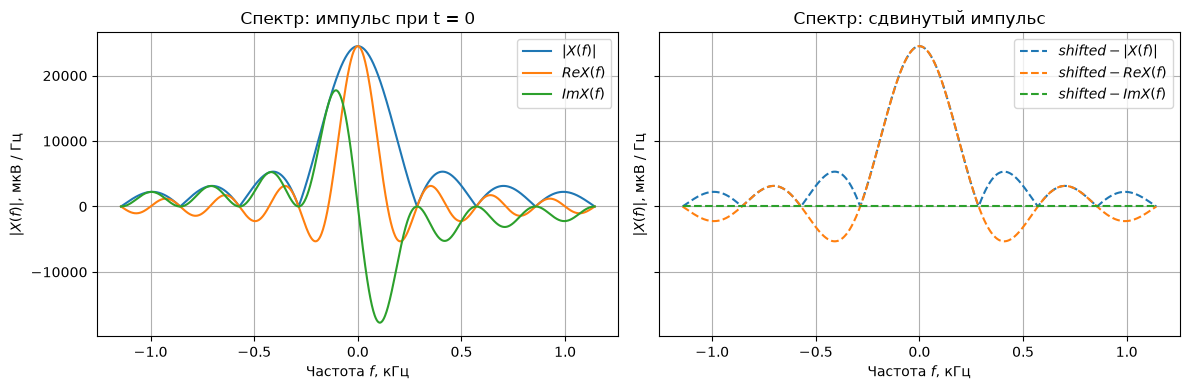

In [42]:
tau=3500*1e-6 #3500 мкс

f_band=np.linspace(-4/tau, 4/tau, 1000) # 1000 - число точек в диапазоне, в которых вычисляется X(f)

def boxcar(t, tau):
    if 0<t<tau:
        return 7 # 0.1 В
    else:
        return 0.0 # 0 В

def boxcar_shift(t, tau):
    if -tau/2<t<tau/2:
        return 7 # 0.1 В
    else:
        return 0.0 # 0 В
    
t_band=np.linspace(-2*tau, 2*tau, 1024)
plt.figure(figsize=[8, 4])
plt.plot(t_band*1e6, [boxcar(t, tau) for t in t_band])
plt.plot(t_band*1e6, [boxcar_shift(t, tau) for t in t_band])
plt.xlabel("Время $t$, мкс")
plt.ylabel("$x(t)$, В")
plt.title("Сигнал")
plt.tight_layout() 
plt.grid()
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey = True)
ax1.plot(f_band/1e3, fourier_transform(signal=boxcar, f_band=f_band, tau=tau, t1=-2*tau, t2=2*tau, res_type="abs")*1e6, label='$|X(f)|$')
ax1.plot(f_band/1e3, fourier_transform(signal=boxcar, f_band=f_band, tau=tau, t1=-2*tau, t2=2*tau, res_type="Re")*1e6, label='${Re }X(f)$')
ax1.plot(f_band/1e3, fourier_transform(signal=boxcar, f_band=f_band, tau=tau, t1=-2*tau, t2=2*tau, res_type="Im")*1e6, label='${Im }X(f)$')
ax1.set_xlabel("Частота $f$, кГц")
ax1.set_ylabel("$|X(f)|$, мкВ / Гц")
ax1.set_title("Спектр: импульс при t = 0")
ax1.legend(loc='best')
ax1.grid()

ax2.plot(f_band/1e3, fourier_transform(signal=boxcar_shift, f_band=f_band, tau=tau, t1=-2*tau, t2=2*tau, res_type="abs")*1e6, label='$shifted - |X(f)|$', linestyle='--')
ax2.plot(f_band/1e3, fourier_transform(signal=boxcar_shift, f_band=f_band, tau=tau, t1=-2*tau, t2=2*tau, res_type="Re")*1e6, label='$shifted - {Re }X(f)$', linestyle='--')
ax2.plot(f_band/1e3, fourier_transform(signal=boxcar_shift, f_band=f_band, tau=tau, t1=-2*tau, t2=2*tau, res_type="Im")*1e6, label='$shifted - {Im }X(f)$', linestyle='--')
ax2.set_xlabel("Частота $f$, кГц")
ax2.set_ylabel("$|X(f)|$, мкВ / Гц")
ax2.set_title("Спектр: сдвинутый импульс")
ax2.legend(loc='best', bbox_to_anchor=(1, 1))
ax2.grid()

plt.tight_layout()
plt.show()

## Задача 2.3. Спектр отрезка синусоиды

|  Варианты:  |  1  |  2  |  3  |  4  |  5  |  6 |  7  |  8  |  9  | 10 |  11 |  12 |
|:-----------:|:---:|:---:|:---:|:---:|:---:|:--:|:---:|:---:|:---:|:--:|:---:|:---:|
|  $f_0$**, кГц** |  10 | 100 |  60 |  40 |  65 | 90 |  30 |  20 |  55 | 75 |  35 |  50 |
| $\tau$**, мкс** | 500 | 50  | 100 | 125 | 100 | 55 | 200 | 225 | 109 | 60 | 171 | 100 |

Ниже приведен пример вычисления спектральной плотности для отрезка синусоиды $x(t)=\sin(2\pi f_0 t)$ c частотой $f_0=10$ кГц длительностью  $\tau=500$  мкс. 

Для заданных параметров  $f_0$  и  $\tau$  из таблицы, построить $|X(f)|$ для отрезка синусоиды $x(t)=\sin(2\pi f_0 t)$ c частотой $f_0$ длительностью  $\tau$. 

1) Сравнить положение главных спектральных максимумов с частотой синусоиды. 

2) Повторить вычисления для отрезка синусоиды, взвешанного окном Ханна соотвествующей длины. Сравнить ширину главного лепестка на нулевом уровне и значение  $|X(f)|$ на частоте $f_0$ для сигнала $x(t)$, взвешанного прямоугольным окном и окном Ханна.

3) Сравнить спектр периодического сигнала  $x(t)=\sin(2\pi f_0 t)$ с получившимися графиками. 

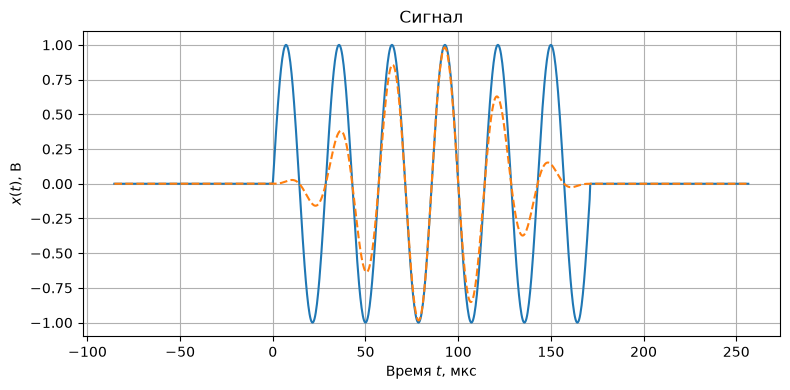

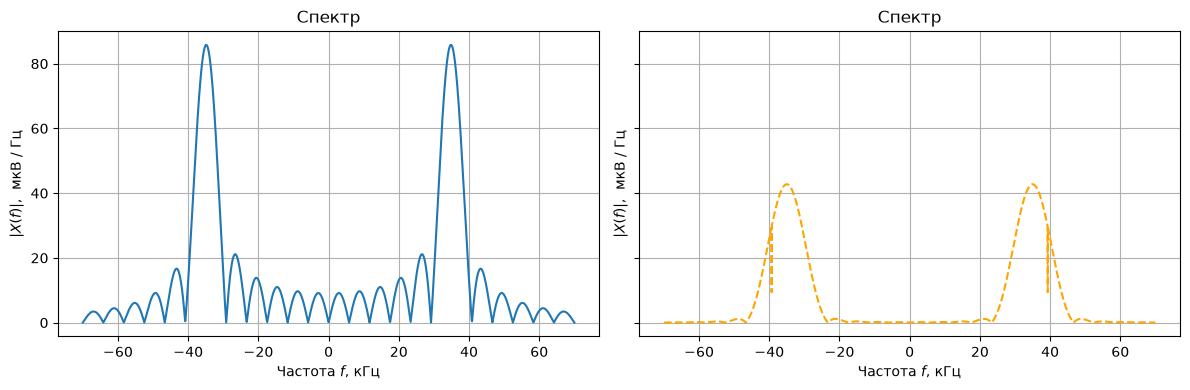

In [49]:
f0=35*1e3       # 35 кГц
tau=171*1e-6    # 171 мкс

def sin_with_boxcar(t, tau):                            
    if 0<=t<=tau:
        # случай прямоугольного окна
        return np.sin(2*np.pi*f0*t) 
        # случай окна Ханна
        # return np.sin(2*np.pi*f0*t) * (0.5+0.5*np.cos(np.pi*(t-tau/2)/(tau/2)))
    else:
        return 0.0

def sin_with_hanncar(t, tau):                            
    if 0<=t<=tau:
        # случай прямоугольного окна
        # return np.sin(2*np.pi*f0*t) 
        # случай окна Ханна
        return np.sin(2*np.pi*f0*t) * (0.5+0.5*np.cos(np.pi*(t-tau/2)/(tau/2)))
    else:
        return 0.0
    
f_band=np.linspace(-2*f0, 2*f0, 2000) 

t_band=np.linspace(-0.5*tau, 1.5*tau, 1024)
plt.figure(figsize=[8, 4])
plt.plot(t_band*1e6, [sin_with_boxcar(t, tau) for t in t_band])
plt.plot(t_band*1e6, [sin_with_hanncar(t, tau) for t in t_band], linestyle='--')
plt.title("Сигнал")
plt.xlabel("Время $t$, мкс")
plt.ylabel("$x(t)$, В")
plt.tight_layout() 
plt.grid()
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey = True)

# ax1.figure(figsize=[8, 4])
ax1.plot(f_band/1e3, fourier_transform(signal=sin_with_boxcar, f_band=f_band, tau=tau, t1=-2*tau, t2=2*tau, res_type="abs")*1e6)
ax1.set_title("Спектр")
ax1.set_xlabel("Частота $f$, кГц")
ax1.set_ylabel("$|X(f)|$,  мкВ / Гц")
ax1.grid()

# ax2.figure(figsize=[8, 4])
ax2.plot(f_band/1e3, fourier_transform(signal=sin_with_hanncar, f_band=f_band, tau=tau, t1=-2*tau, t2=2*tau, res_type="abs")*1e6, linestyle='--', color='orange')
ax2.set_title("Спектр")
ax2.set_xlabel("Частота $f$, кГц")
ax2.set_ylabel("$|X(f)|$,  мкВ / Гц")
ax2.grid()


plt.tight_layout()
plt.show()

## Задача 2.4. Спектр пачки равноотстоящих импульсов

|    Варианты:    |  1  |  2  |  3  |  4  |  5  |  6  |  7  |  8  |  9  |  10 |  11 |  12 |
|:---------------:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
|        N        |  3  |  4  |  3  |  4  |  3  |  4  |  3  |  4  |  3  |  4  |  3  |  4  |
| $\tau$**, мкс**     | 300 | 50  | 100 | 125 | 250 | 60  | 200 | 400 | 500 | 150 | 450 | 100 |
| $T_{period}$**, мкс** | 600 | 125 | 200 | 275 | 500 | 100 | 400 | 700 | 800 | 300 | 810 | 200 |

Ниже приведен пример вычисления спектр пачки из $N=4$ равноотстоящих импульсов длительностью $\tau = 100$ мкс с периодом повторения $T_{period}=400$ мкс.

Повторить вычисления для заданных значений $N$, $\tau$, $T_{period}$. Сравнить получившийся график с аналитическим выражением для спектра.


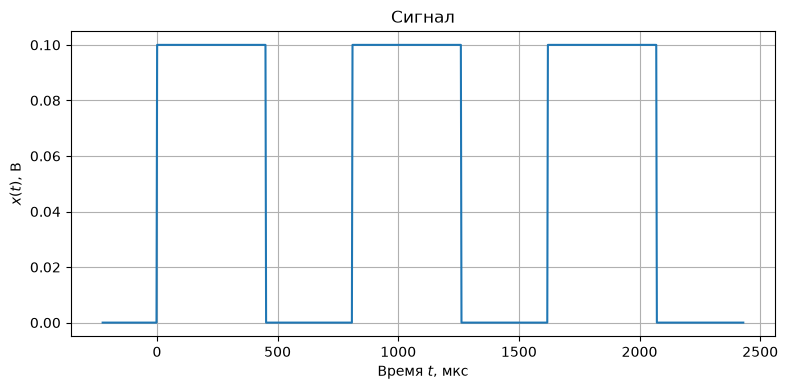

/tmp/ipykernel_15629/1525074502.py:24: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  Re=np.array([integrate.quad(integrate_function, t1, t2, args=(signal, f, tau, True))[0] for f in f_band])
/tmp/ipykernel_15629/1525074502.py:24: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  Re=np.array([integrate.quad(integrate_function, t1, t2, args=(signal, f, tau, True))[0] for f in f_band])
/tmp/ipykernel_15629/1525074502.py:25: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is

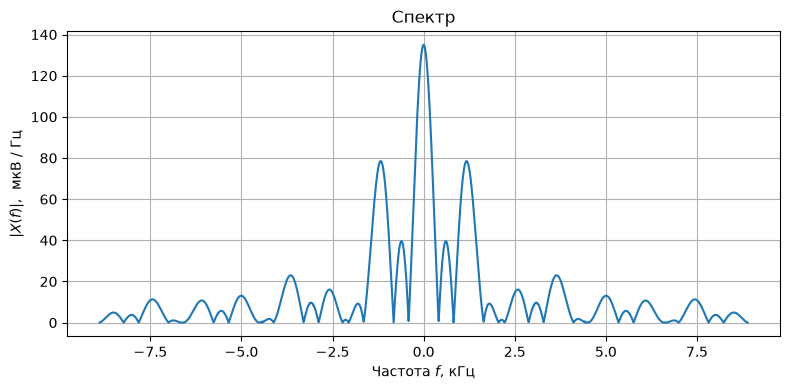

In [28]:
N=3
tau=450e-6 #450 мкс
period = 810e-6 

f_band=np.linspace(-4/tau, 4/tau, 2000) # 2000 - число точек в диапазоне, в которых вычисляется X(f)

def boxcar(t, tau):
    
    for n in range(N):
        tau0 = period * n
        tau1 = tau + period * n
        if tau0 < t < tau1:
            return 0.1 # 0.1 В
    return 0.0 # 0 В
    
t_band=np.linspace(-0.5*tau, N*period, 1024)
plt.figure(figsize=[8, 4])
plt.plot(t_band*1e6, [boxcar(t, tau) for t in t_band])
plt.xlabel("Время $t$, мкс")
plt.ylabel("$x(t)$, В")
plt.title("Сигнал")
plt.tight_layout() 
plt.grid()
plt.show()

plt.figure(figsize=[8, 4])
plt.plot(f_band/1e3, fourier_transform(signal=boxcar, f_band=f_band, tau=tau, t1=0, t2=N*period, res_type="abs")*1e6)
plt.title("Спектр")
plt.xlabel("Частота $f$, кГц")
plt.ylabel("$|X(f)|$,  мкВ / Гц")
plt.tight_layout() 
plt.grid()
plt.show()

# Занятие 3. Эффект наложения спектров при дискретизации сигналов.

## Задача 3.1. Эффект наложения при дискретизации прямоугольного импульса

|  Варианты:  |  1  |  2  |   3  |   4  |  5  |   6  |  7  |   8  |   9  |  10 |  11  |  12  |
|:-----------:|:---:|:---:|:----:|:----:|:---:|:----:|:---:|:----:|:----:|:---:|:----:|:----:|
| $\tau$**, мкс** | 100 | 500 | 1000 | 5000 | 400 | 2000 | 300 | 1500 | 3000 | 800 | 3500 | 4000 |


Рассмотреть прямоугольный импульс длительностью $1.05\tau$. Дискретизовать его с частотой $f_s  = 10/ \tau $.  Построить спектр прямоугольного импульса и полученного дискретизованного сигнала. 

Пронаблюдать наложение спектра при дискретизации. 

Найти сигнал,  который дискретизуется такой же последовательностью, как и прямоугольный импульс, но при этом не наблюдается эффект наложения (сигнал, который восстанавливается с помощью интерполяционного ряда Котельникова).

In [29]:
def DTFT_abs3(xk, fs, M=2048):
    res=abs(np.fft.fftshift(np.fft.fft(xk, M)))
    return fs*np.arange(-1.5, 1.5, 1/M), np.hstack((res, res, res)) 

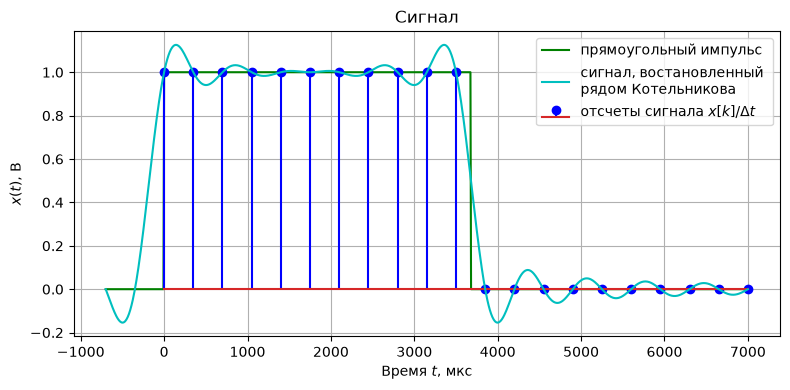

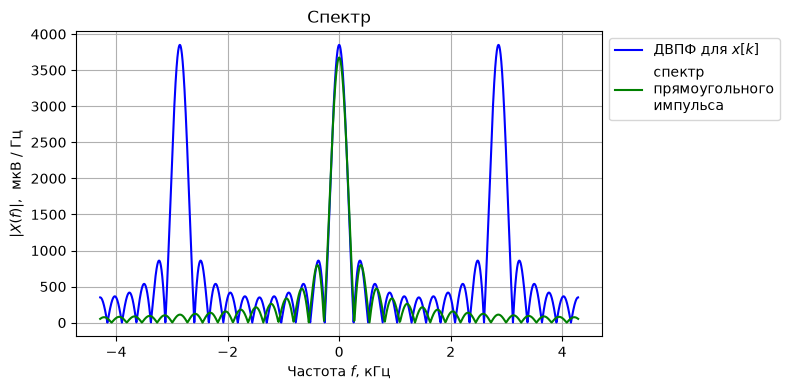

In [30]:
tau=3500*1e-6 #3500 мкс
fs=10/tau

f_band=np.linspace(-1.5*fs, 1.5*fs, 1000) # 1000 - число точек в диапазоне, в которых вычисляется X(f)

def boxcar(t, tau):
    if 0 <= t <= 1.05*tau:
        return 1.0 
    elif np.isclose(t, 1.05*tau, atol=1e-12) or np.isclose(t, 0, atol=1e-12):
        return 1.0 
    else:
        return 0.0 

def sinc_phi(t, k, fs):
    dt=1/fs
    if np.isclose(0, t-k*dt):
        return 1.0
    else:
        return np.sin(np.pi*fs*(t-k*dt))/(np.pi*fs*(t-k*dt))
    
def sinc_interp(t, xk):
    return sum([xk[k]*fs*sinc_phi(t, k, fs) for k in range(len(xk))])

tk = np.arange(0, 2*tau+1.0/fs, 1.0/fs, dtype=float)
xk = np.array([(1/fs)*boxcar(tk1, tau) for tk1 in tk])
    
t_band=np.linspace(-0.2*tau, 2*tau, 1024)
plt.figure(figsize=[8, 4])
plt.plot(t_band*1e6, [boxcar(t, tau) for t in t_band], 'g', label='прямоугольный импульс')
plt.stem(tk*1e6, xk*fs, linefmt='b', markerfmt='bo', label='отсчеты сигнала $x[k]/{\\Delta t}$')



plt.plot(t_band*1e6, np.array([sinc_interp(t, xk) for t in t_band]), 'c', label='сигнал, востановленный \nрядом Котельникова')

plt.title("Сигнал")
plt.xlabel("Время $t$, мкс")
plt.ylabel("$x(t)$, В")
plt.grid()
plt.legend(loc='best', bbox_to_anchor=(1, 1))
plt.tight_layout() 
plt.show()

plt.figure(figsize=[8, 4])


DFTF_plot=DTFT_abs3(xk, fs)
plt.plot(DFTF_plot[0]/1e3, DFTF_plot[1]*1e6, 'b', label='ДВПФ для $x[k]$')

plt.plot(f_band/1e3, fourier_transform(signal=boxcar, f_band=f_band, tau=tau, t1=-2*tau, t2=2*tau, res_type="abs")*1e6, 
         'g', label='спектр\nпрямоугольного\nимпульса')

plt.title("Спектр")
plt.xlabel("Частота $f$, кГц")
plt.ylabel("$|X(f)|$,  мкВ / Гц")
plt.grid()
plt.legend(loc='best', bbox_to_anchor=(1, 1))
plt.tight_layout() 
plt.show()

## Задача 3.2. Эффект наложения при прореживании сигнала

| Варианты: | 1  | 2  | 3  | 4  | 5  | 6  | 7  | 8  | 9  | 10 | 11 | 12 |
|:---------:|----|----|----|----|----|----|----|----|----|----|----|----|
| $K_1$     | 35 | 10 | 20 | 25 | 15 | 40 | 20 | 15 | 40 | 35 | 10 | 25 |
| $K_2$     | 70 | 60 | 65 | 80 | 75 | 90 | 85 | 60 | 95 | 80 | 70 | 75 |


Выполнить прореживание (downsampling) сигнала камертона из файла `tuning-fork.wav` (основная частота сигнала 440 Гц, частота дискретизации 44100 Гц) без предварительной фильтрации, оставляя в одном случае каждый $K_1$-ый, а в другом каждый $K_2$-ый отсчет сигнала. В чем принципиальное отличие между спектрами получившихся сигналов и какими эффектами оно обусловлено? 

In [31]:
def DTFT_abs(xk, fs, M=2**17):
    res=abs(np.fft.fftshift(np.fft.fft(xk, M)))
    return fs*np.arange(-0.5, 0.5, 1/M), np.hstack((res)) 

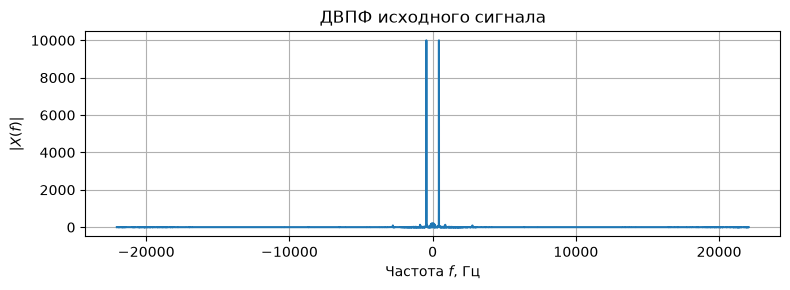

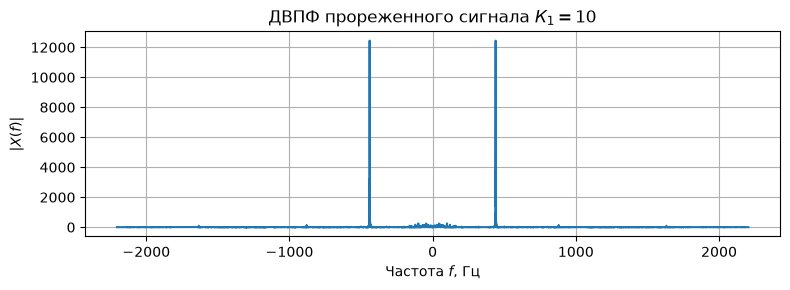

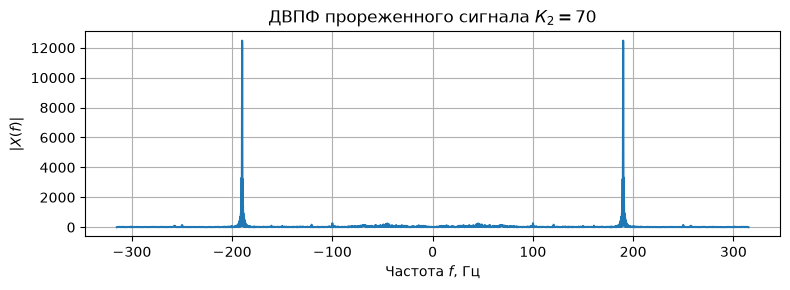

In [32]:
fs, x=scipy.io.wavfile.read('dataset_lab1/tuning-fork.wav')
#for mono channel 
#x=x[:,1] 

plt.figure(figsize=[8, 3], dpi=100)

DFTF_plot=DTFT_abs(x/fs, fs)
plt.plot(DFTF_plot[0], DFTF_plot[1])
plt.grid()
plt.title("ДВПФ исходного сигнала")
plt.xlabel("Частота $f$, Гц")
plt.ylabel("$|X(f)|$")
plt.tight_layout() 

# downsampling
plt.figure(figsize=[8, 3], dpi=100)
K1=10
y=x[::K1]
DFTF_plot=DTFT_abs(y/(fs/K1), fs/K1)
plt.plot(DFTF_plot[0], DFTF_plot[1])
plt.grid()
plt.title("ДВПФ прореженного сигнала $К_1=$%i" %K1)
plt.xlabel("Частота $f$, Гц")
plt.ylabel("$|X(f)|$")
plt.tight_layout()
plt.show()

# downsampling
plt.figure(figsize=[8, 3], dpi=100)
K2=70
y=x[::K2]
    
DFTF_plot=DTFT_abs(y/(fs/K2), fs/K2)
plt.plot(DFTF_plot[0], DFTF_plot[1])
plt.grid()
plt.title("ДВПФ прореженного сигнала $К_2=$%i" %K2)
plt.xlabel("Частота $f$, Гц")
plt.ylabel("$|X(f)|$")
plt.tight_layout() 
plt.show()